# 03 — Dự đoán Top-5 bằng ViT-B/16 Pretrained Gốc (Chưa Fine-tune)

Notebook này kiểm tra khả năng suy luận **zero-shot / off-the-shelf** của mô hình `torchvision.models.vit_b_16(weights=ViT_B_16_Weights.IMAGENET1K_V1)` trên một số ảnh mẫu thuộc tập **Oxford-IIIT Pet** (37 giống chó và mèo) khi **chưa thay head và chưa fine-tune**.

**Mục tiêu:**
1. Quan sát Top-5 nhãn ImageNet-1K và xác suất softmax mà ViT-B/16 gốc dự đoán cho ảnh mèo và chó trong Oxford-IIIT Pet.
2. Phân tích sự khác biệt giữa không gian nhãn ImageNet-1K (1.000 lớp tổng quát) và bài toán phân loại mịn 37 giống thú cưng, từ đó lý giải vì sao cần fine-tune.

In [1]:
import os
import sys
from pathlib import Path

# Ho tro chay ca tren Google Colab lan may cuc bo
if "google.colab" in sys.modules:
    repo_dir = Path("/content/vit-oxford-pets")
    if not repo_dir.exists():
        !git clone -q https://github.com/duyenphung206-sudo/vit-oxford-pets.git /content/vit-oxford-pets
    os.chdir(repo_dir)
    !pip install -q -r requirements.txt
    DATA_ROOT = "/content/data"
else:
    DATA_ROOT = "data"

print("Working directory:", Path.cwd())
print("Dataset root:", DATA_ROOT)

Working directory: /content/vit-oxford-pets
Dataset root: /content/data


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image, ImageOps
from torchvision import models
from torchvision.datasets import OxfordIIITPet

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 1. Tải mô hình ViT-B/16 Pretrained gốc (ImageNet-1K)

Giữ nguyên đầu phân loại gốc `Linear(768 -> 1000)` của ImageNet-1K và phép tiền xử lý chuẩn `ViT_B_16_Weights.IMAGENET1K_V1.transforms()`.

In [3]:
weights = models.ViT_B_16_Weights.IMAGENET1K_V1
imagenet_categories = weights.meta["categories"]
preprocess = weights.transforms()

model = models.vit_b_16(weights=weights).to(device).eval()
print(f"So lop dau ra ImageNet-1K: {len(imagenet_categories)}")
print(f"Head goc: {model.heads.head}")
print(f"Transform danh gia: {preprocess}")

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:03<00:00, 86.8MB/s]


So lop dau ra ImageNet-1K: 1000
Head goc: Linear(in_features=768, out_features=1000, bias=True)
Transform danh gia: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


## 2. Chọn các ảnh mẫu đa dạng từ Oxford-IIIT Pet (Mèo & Chó)

Ta chọn 8 ảnh đại diện thuộc 8 giống khác nhau trong tập `test` của Oxford-IIIT Pet:
- **4 giống mèo:** `Abyssinian`, `Bengal`, `Sphynx`, `Siamese`
- **4 giống chó:** `beagle`, `pug`, `samoyed`, `shiba_inu`

In [5]:
dataset = OxfordIIITPet(root=DATA_ROOT, split="test", download=True)
pet_classes = dataset.classes
print(f"Tong so anh tap test: {len(dataset)} | So giong Oxford-IIIT Pet: {len(pet_classes)}")

target_breeds = [
    "Abyssinian",
    "Bengal",
    "Sphynx",
    "Siamese",
    "Beagle",
    "Pug",
    "Samoyed",
    "Shiba Inu",
]

# Lay anh dau tien cua moi giong muc tieu trong tap test (su dung lowercase de so sanh vi ten file luon viet thuong)
selected_samples = []
seen_breeds = set()
target_breeds_lower = [b.lower().replace(" ", "_") for b in target_breeds]

for idx, img_path in enumerate(dataset._images):
    breed_name = img_path.stem.rsplit("_", 1)[0].lower()
    if breed_name in target_breeds_lower and breed_name not in seen_breeds:
        seen_breeds.add(breed_name)
        image, label_idx = dataset[idx]
        image = ImageOps.exif_transpose(image).convert("RGB")
        selected_samples.append({
            "index": idx,
            "image_id": img_path.stem,
            "true_breed": pet_classes[label_idx],
            "image": image,
        })
    if len(selected_samples) == len(target_breeds):
        break

# Sap xep dung thu tu target_breeds
order_map = {name: i for i, name in enumerate(target_breeds)}
selected_samples.sort(key=lambda item: order_map[item["true_breed"]])

for s in selected_samples:
    print(f"- {s['image_id']} (true breed: {s['true_breed']})")

Tong so anh tap test: 3669 | So giong Oxford-IIIT Pet: 37
- Abyssinian_201 (true breed: Abyssinian)
- Bengal_192 (true breed: Bengal)
- Sphynx_20 (true breed: Sphynx)
- Siamese_209 (true breed: Siamese)
- beagle_195 (true breed: Beagle)
- pug_193 (true breed: Pug)
- samoyed_191 (true breed: Samoyed)
- shiba_inu_1 (true breed: Shiba Inu)


## 3. Suy luận Top-5 nhãn ImageNet-1K trên các ảnh mẫu

In [6]:
@torch.inference_mode()
def predict_top5_imagenet(pil_image: Image.Image) -> list[tuple[str, float]]:
    tensor = preprocess(pil_image).unsqueeze(0).to(device)
    probs = model(tensor).float().softmax(dim=-1)[0]
    values, indices = probs.topk(5)
    return [
        (imagenet_categories[idx], float(prob))
        for idx, prob in zip(indices.cpu().tolist(), values.cpu().tolist())
    ]

records = []
for sample in selected_samples:
    top5 = predict_top5_imagenet(sample["image"])
    sample["top5"] = top5
    records.append({
        "Image ID": sample["image_id"],
        "True Pet Breed": sample["true_breed"],
        "Top-1 ImageNet": f"{top5[0][0]} ({top5[0][1]*100:.1f}%)",
        "Top-2 ImageNet": f"{top5[1][0]} ({top5[1][1]*100:.1f}%)",
        "Top-3 ImageNet": f"{top5[2][0]} ({top5[2][1]*100:.1f}%)",
        "Top-4 ImageNet": f"{top5[3][0]} ({top5[3][1]*100:.1f}%)",
        "Top-5 ImageNet": f"{top5[4][0]} ({top5[4][1]*100:.1f}%)",
    })

df_results = pd.DataFrame(records)
df_results

,Image ID,True Pet Breed,Top-1 ImageNet,Top-2 ImageNet,Top-3 ImageNet,Top-4 ImageNet,Top-5 ImageNet
0,Abyssinian_201,Abyssinian,Egyptian cat (47.7%),tabby (6.2%),tiger cat (3.6%),mouse (3.2%),joystick (3.1%)
1,Bengal_192,Bengal,Egyptian cat (91.0%),tabby (0.7%),tiger cat (0.5%),leopard (0.2%),jaguar (0.1%)
2,Sphynx_20,Sphynx,Chihuahua (36.7%),Mexican hairless (25.2%),Ibizan hound (7.1%),French bulldog (4.7%),Egyptian cat (4.2%)
3,Siamese_209,Siamese,Siamese cat (89.5%),Egyptian cat (0.1%),lynx (0.1%),Welsh springer spaniel (0.0%),teddy (0.0%)
4,beagle_195,Beagle,Brittany spaniel (70.0%),beagle (17.7%),Walker hound (0.8%),English foxhound (0.3%),Saint Bernard (0.2%)
5,pug_193,Pug,pug (80.8%),Brabancon griffon (2.9%),French bulldog (0.5%),Chihuahua (0.5%),Boston bull (0.2%)
6,samoyed_191,Samoyed,Samoyed (89.1%),keeshond (0.3%),malamute (0.3%),Pomeranian (0.2%),Great Pyrenees (0.1%)
7,shiba_inu_1,Shiba Inu,dingo (44.6%),basenji (5.5%),kelpie (4.9%),Pembroke (1.9%),redbone (1.7%)


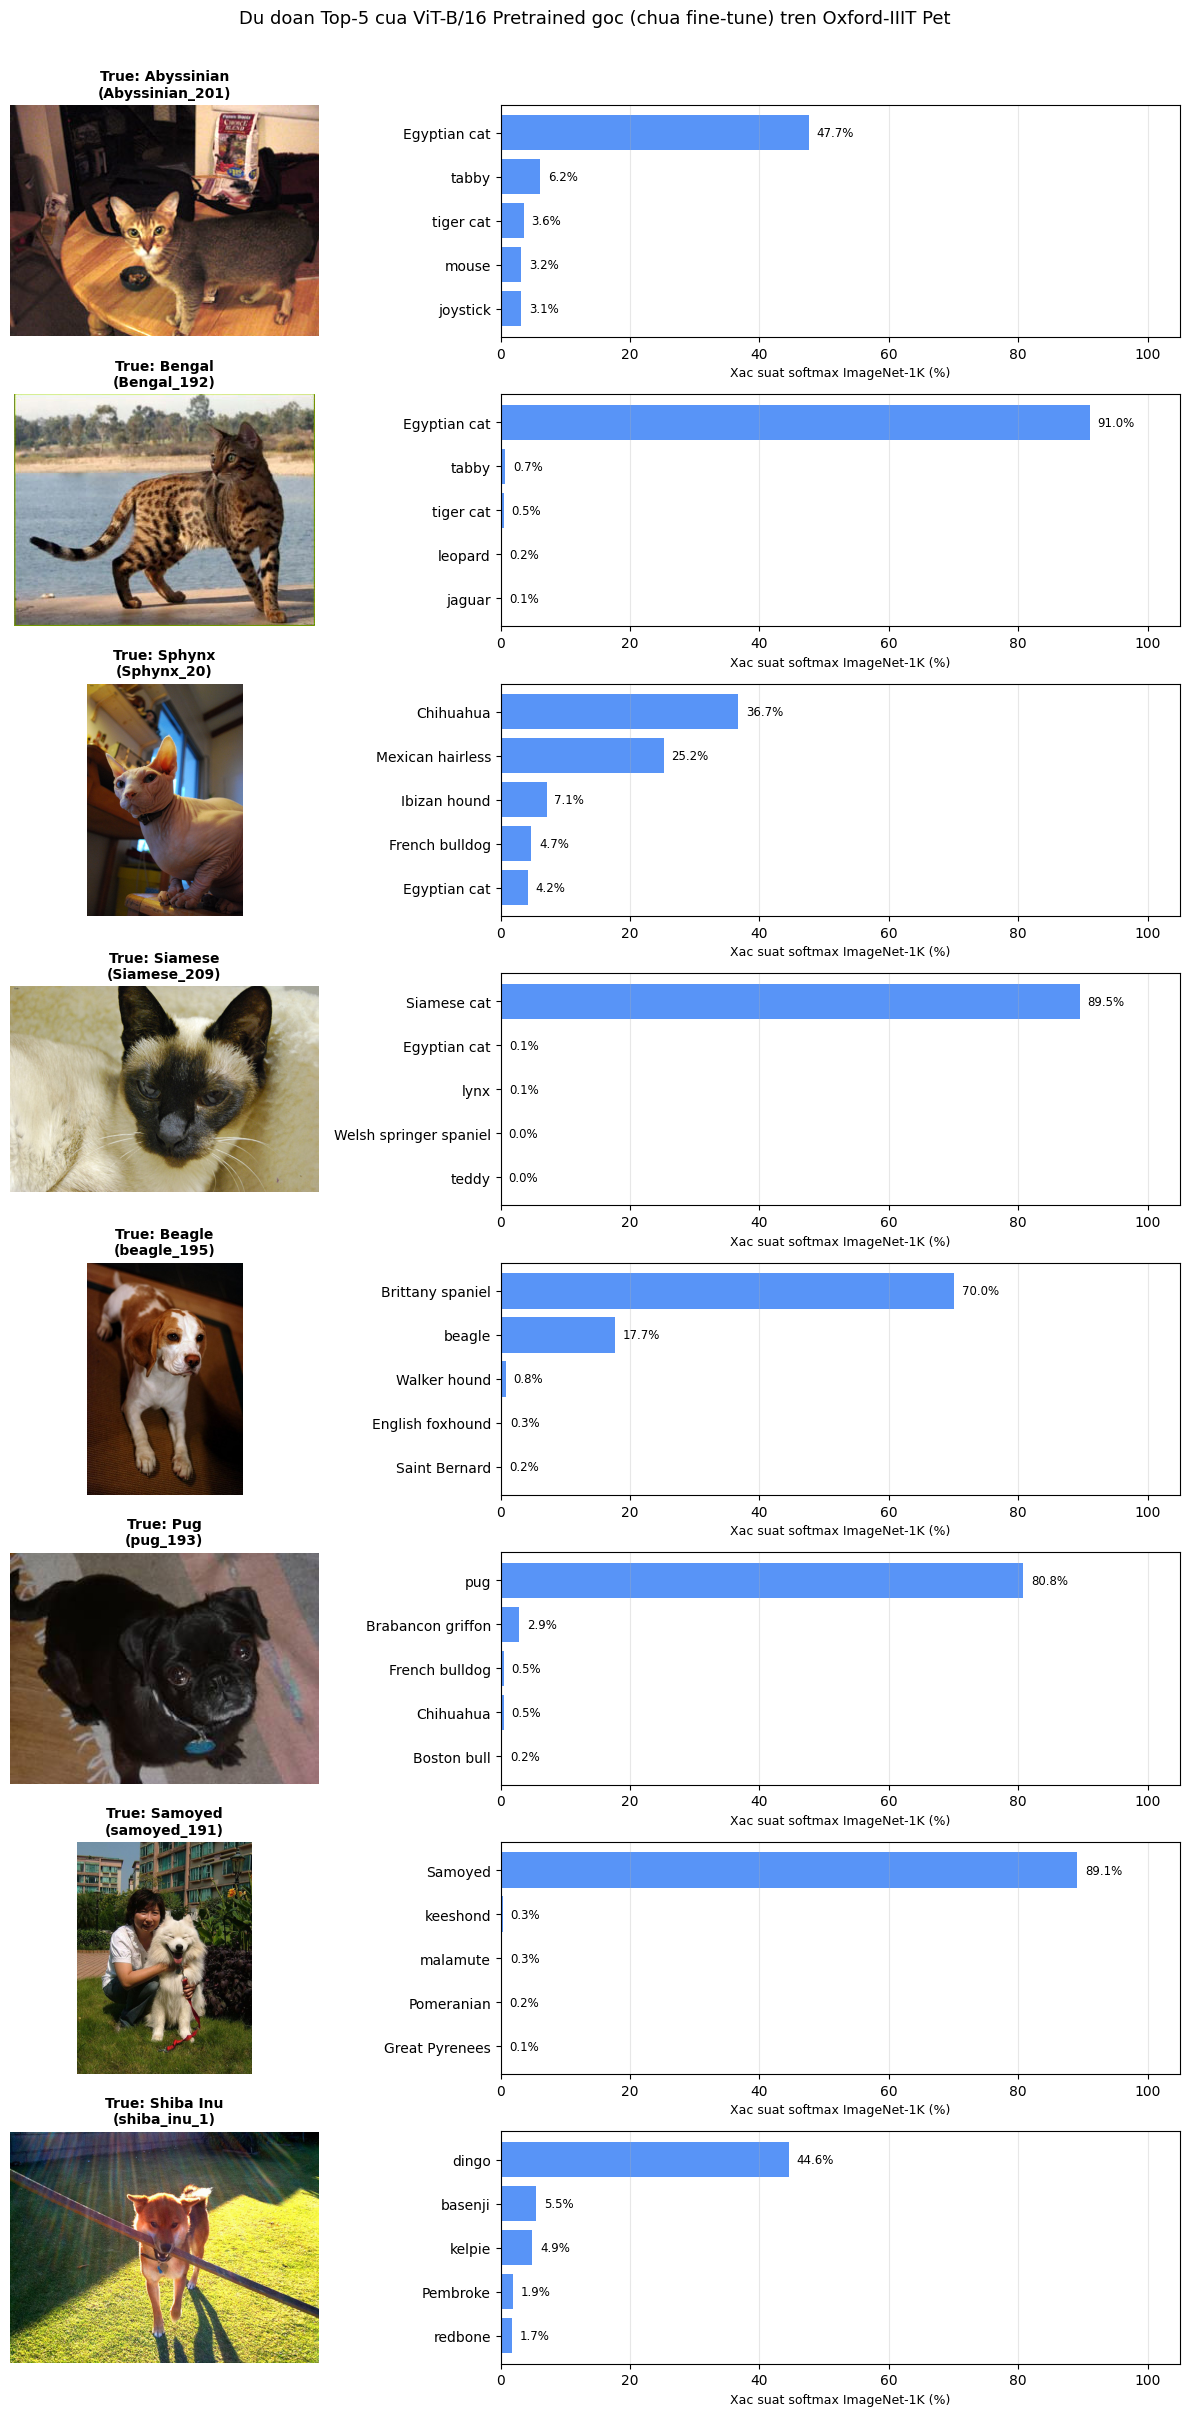

In [7]:
# Truc quan hoa anh goc kem bieu do thanh ngang Top-5 xac suat ImageNet
n_samples = len(selected_samples)
fig, axes = plt.subplots(n_samples, 2, figsize=(12, 3.0 * n_samples), gridspec_kw={"width_ratios": [1, 2.2]})

for row_idx, sample in enumerate(selected_samples):
    ax_img, ax_bar = axes[row_idx]
    ax_img.imshow(sample["image"])
    ax_img.axis("off")
    ax_img.set_title(f"True: {sample['true_breed']}\n({sample['image_id']})", fontsize=10, fontweight="bold")

    labels = [name for name, _ in reversed(sample["top5"])]
    scores = [prob * 100 for _, prob in reversed(sample["top5"])]
    bars = ax_bar.barh(labels, scores, color="#3b82f6", alpha=0.85)
    ax_bar.set_xlim(0, 105)
    ax_bar.set_xlabel("Xac suat softmax ImageNet-1K (%)", fontsize=9)
    ax_bar.grid(axis="x", alpha=0.3)
    for bar, score in zip(bars, scores):
        ax_bar.text(score + 1.2, bar.get_y() + bar.get_height() / 2, f"{score:.1f}%", va="center", fontsize=8.5)

fig.suptitle("Du doan Top-5 cua ViT-B/16 Pretrained goc (chua fine-tune) tren Oxford-IIIT Pet", fontsize=13, y=1.005)
fig.tight_layout()
plt.show()

## 4. Nhận xét: Vì sao vẫn cần Fine-tune ViT-B/16?

Từ bảng kết quả và biểu đồ Top-5 ở trên, có thể rút ra **4 lý do cốt lõi** giải thích vì sao không thể dùng trực tiếp `ViT-B/16` pretrained gốc mà bắt buộc phải **fine-tune** trên Oxford-IIIT Pet:

1. **Không gian nhãn không tương thích (Label Space Mismatch — 1.000 lớp ImageNet vs. 37 giống Oxford-IIIT Pet):**
   - Bộ nhãn ImageNet-1K chỉ có khoảng ~118 giống chó và chỉ **5–7 nhãn mèo nhà** (*tabby*, *tiger cat*, *Persian cat*, *Siamese cat*, *Egyptian cat*). Nhiều giống mèo phổ biến trong Oxford-IIIT Pet như **Abyssinian**, **Bengal**, **Sphynx**, **Ragdoll**, **Maine Coon**, **British Shorthair**, **Russian Blue**... **hoàn toàn không tồn tại** trong danh mục 1.000 lớp của ImageNet.
   - Do đó, với ảnh mèo *Abyssinian*, *Bengal* hay *Sphynx*, mô hình buộc phải gán sang các nhãn gần nhất về mặt thị giác như *Egyptian cat*, *tabby*, *tiger cat* hoặc thậm chí động vật hoang dã (*lynx*, *cougar*).

2. **Phân tán xác suất ở các giống gần nghĩa (Probability Dilution):**
   - Trong ImageNet-1K, các giống chó gần nhau (ví dụ nhóm chó săn tai cụp như *beagle*, *English foxhound*, *basset*, *Walker hound*) chia sẻ xác suất dự đoán, khiến độ tự tin Top-1 bị suy giảm dù mô hình nhận diện đúng loài vật.
   - Ngược lại, một số nhãn trong ImageNet bị trùng lặp ngữ nghĩa hoặc quá rộng, không ánh xạ 1–1 sang 37 lớp chuẩn của Oxford-IIIT Pet.

3. **Khác biệt giữa phân loại tổng quát (Coarse-grained) và phân loại mịn (Fine-grained):**
   - Lớp tuyến tính cuối cùng của mô hình gốc (`heads.head: Linear(768 → 1000)`) được huấn luyện để phân biệt 1.000 khái niệm rất rộng (xe cộ, đồ gia dụng, thực vật, chim, cá, chó, mèo...), thay vì tập trung vào các đặc trưng tinh vi phân biệt 37 giống thú cưng (hình dáng tai, độ dài mõm, kết cấu lông, hoa văn vằn/đốm).

4. **Vai trò của Fine-tuning trên nền tảng Pretrained Backbone:**
   - Mặc dù head 1.000 lớp không dùng trực tiếp được, các khối Self-Attention của `ViT-B/16` đã học được biểu diễn thị giác rất giàu thông tin về hình thái động vật và kết cấu lông.
   - Khi thay thế head bằng `Linear(768 → 37)` khởi tạo bằng 0 và tinh chỉnh (fine-tune) trên tập huấn luyện Oxford-IIIT Pet (như thí nghiệm **E4** trong dự án), mô hình nhanh chóng thích nghi ranh giới quyết định sang đúng 37 giống cần phân loại và đạt **95.47% ± 0.08% validation accuracy**.